# Proyecto completo de machine learning - Juicios por brujería en Europa

Entre los siglos XIV y XIX se juzgó por brujería en Europa a decenas de miles de personas. Algunos juicios acabaron con ejecuciones y otros no. El objetivo de este proyecto es crear un modelo que prediga **si un juicio acabó con alguna ejecución**.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/89/Wickiana5.jpg" height="350px">

**Vídeo explicativo del proyecto:** https://youtu.be/CFYIUxl0N8c

**Enlace al Colab:** https://colab.research.google.com/drive/1ecdt-V2lWM1jPBiM62oMlqDNdxF2p_0q?usp=sharing

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Obtención de datos

Los datos vienen del artículo *Witch Trials* (Leeson y Russ, 2018, The Economic Journal): https://doi.org/10.1111/ecoj.12498

Los autores recopilaron los juicios por brujería documentados en los trabajos de más de treinta historiadores y los publicaron en GitHub: https://github.com/JakeRuss/witch-trials

Como el fichero es público, lo cargamos directamente desde su dirección.

In [ ]:
# Cargamos los datos en un dataframe de Pandas
url = "https://raw.githubusercontent.com/JakeRuss/witch-trials/master/data/trials.csv"
trials = pd.read_csv(url)

## 2. Descripción de los datos

Cada fila es un juicio, y en un mismo juicio se puede juzgar a varias personas.

Los nombres de las columnas y de los países vienen en inglés, así que los pasamos a español. Estos son los atributos, con su nombre original entre paréntesis:

* `año` (`year`): año del juicio.
* `decada` (`decade`): década del juicio.
* `siglo` (`century`): siglo del juicio (1600 es el siglo XVII).
* `juzgados` (`tried`): número de personas juzgadas.
* `ejecutados` (`deaths`): número de personas ejecutadas.
* `ciudad` (`city`): ciudad o pueblo.
* `provincia` (`gadm.adm2`): provincia o condado.
* `region` (`gadm.adm1`): región.
* `pais` (`gadm.adm0`): país, según las fronteras actuales.
* `longitud` y `latitud` (`lon` y `lat`): coordenadas de la ciudad.
* `fuente` (`record.source`): trabajo del que se ha sacado el registro.

In [ ]:
trials.columns = ["año", "decada", "siglo", "juzgados", "ejecutados", "ciudad", "provincia", "region", "pais", "longitud", "latitud", "fuente"]

trials["pais"] = trials["pais"].replace({
    "United Kingdom": "Reino Unido", "Germany": "Alemania", "Switzerland": "Suiza", "France": "Francia",
    "Belgium": "Bélgica", "Sweden": "Suecia", "Netherlands": "Países Bajos", "Italy": "Italia",
    "Denmark": "Dinamarca", "Spain": "España", "Hungary": "Hungría", "Norway": "Noruega",
    "Luxembourg": "Luxemburgo", "Finland": "Finlandia", "Poland": "Polonia", "Ireland": "Irlanda",
    "Czech Republic": "República Checa"
})

trials.head()

,año,decada,siglo,juzgados,ejecutados,ciudad,provincia,region,pais,longitud,latitud,fuente
0,NaN,1520,1500,1,1.0,NaN,NaN,NaN,Estonia,NaN,NaN,Madar (1990)
1,NaN,1530,1500,1,1.0,NaN,NaN,NaN,Estonia,NaN,NaN,Madar (1990)
2,NaN,1540,1500,5,5.0,NaN,NaN,NaN,Estonia,NaN,NaN,Madar (1990)
3,NaN,1580,1500,7,5.0,NaN,NaN,NaN,Estonia,NaN,NaN,Madar (1990)
4,NaN,1590,1500,11,0.0,NaN,NaN,NaN,Estonia,NaN,NaN,Madar (1990)


In [ ]:
trials.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10940 entries, 0 to 10939
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   año         10009 non-null  float64
 1   decada      10940 non-null  int64  
 2   siglo       10940 non-null  int64  
 3   juzgados    10940 non-null  int64  
 4   ejecutados  7114 non-null   float64
 5   ciudad      5727 non-null   object 
 6   provincia   9893 non-null   object 
 7   region      10781 non-null  object 
 8   pais        10940 non-null  object 
 9   longitud    5137 non-null   float64
 10  latitud     5137 non-null   float64
 11  fuente      10940 non-null  object 
dtypes: float64(4), int64(3), object(5)
memory usage: 1.0+ MB


## 3. Exploración y visualización de los datos

Empezamos viendo cuántos juicios hay de cada país.

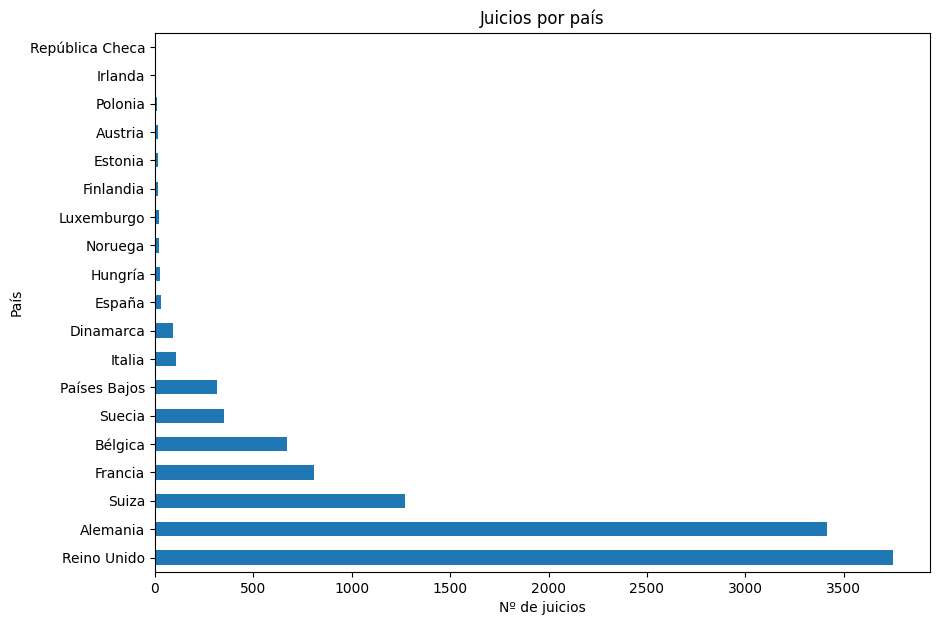

In [ ]:
trials["pais"].value_counts().plot(kind="barh", figsize=(10, 7))
plt.title("Juicios por país")
plt.xlabel("Nº de juicios")
plt.ylabel("País")
plt.show()

Los datos están muy descompensados: Reino Unido y Alemania tienen casi dos de cada tres juicios.

In [ ]:
trials.describe()

,año,decada,siglo,juzgados,ejecutados,longitud,latitud
count,10009.000000,10940.000000,10940.000000,10940.000000,7114.000000,5137.000000,5137.000000
mean,1621.063643,1614.868373,1569.195612,3.952468,2.295895,8.291444,48.552024
std,66.250517,66.680880,72.613899,19.264166,16.298211,2.887349,1.649580
min,1300.000000,1300.000000,1300.000000,1.000000,0.000000,-3.533899,41.385064
25%,1597.000000,1590.000000,1500.000000,1.000000,0.000000,6.154280,47.730300
50%,1630.000000,1620.000000,1600.000000,1.000000,0.000000,8.765020,48.533600
75%,1660.000000,1650.000000,1600.000000,1.000000,1.000000,10.489500,49.758600
max,1850.000000,1850.000000,1800.000000,500.000000,500.000000,19.820054,54.775250


Casi siempre se juzgó a una sola persona, aunque hay casos de hasta 500.

Veamos la evolución en el tiempo.

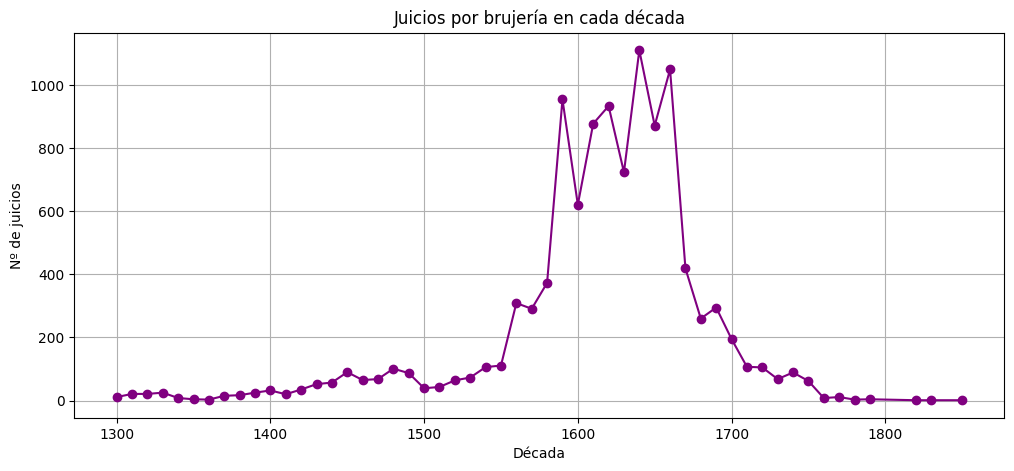

In [ ]:
# Número de juicios registrados en cada década
juicios_por_decada = trials["decada"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(juicios_por_decada.index, juicios_por_decada.values, color="purple", marker="o")
plt.title("Juicios por brujería en cada década")
plt.xlabel("Década")
plt.ylabel("Nº de juicios")
plt.grid()
plt.show()

La gran mayoría de los juicios se concentran entre 1560 y 1670.

Ahora los vemos en el mapa. El tamaño del círculo es el número de personas juzgadas y el color la década.

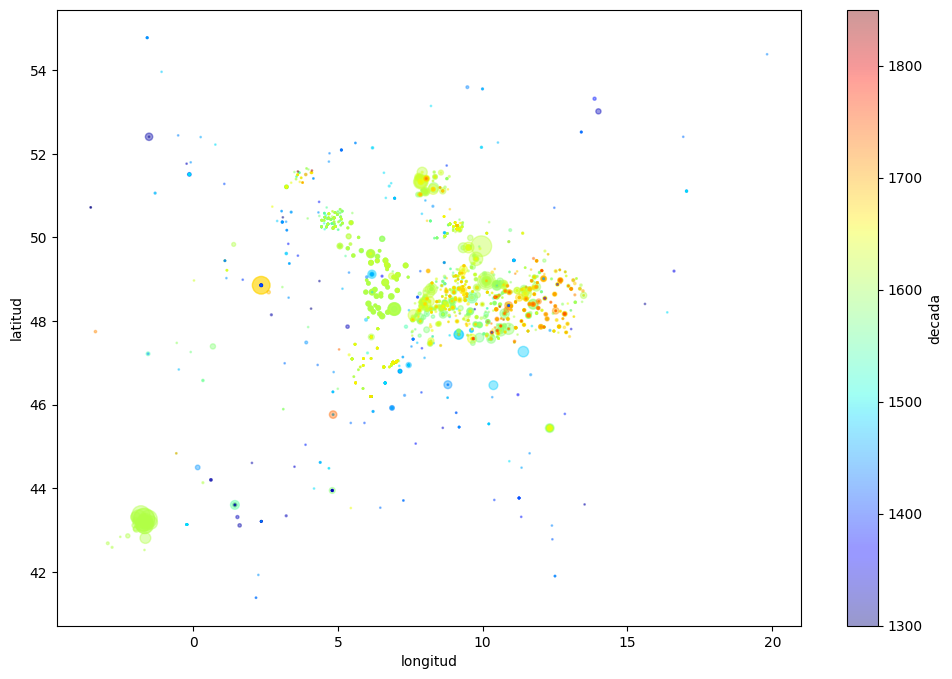

In [ ]:
trials.plot(
    kind="scatter", x="longitud", y="latitud", alpha=0.4, figsize=(12, 8),
    s=trials["juzgados"], c="decada", cmap="jet", colorbar=True
)
plt.show()

La mayor concentración está en el sur de Alemania. Los círculos grandes de abajo a la izquierda son los juicios de Navarra y el País Vasco de 1610.

En el mapa solo salen los juicios que tienen coordenadas, por eso Reino Unido casi no aparece.

### Correlaciones

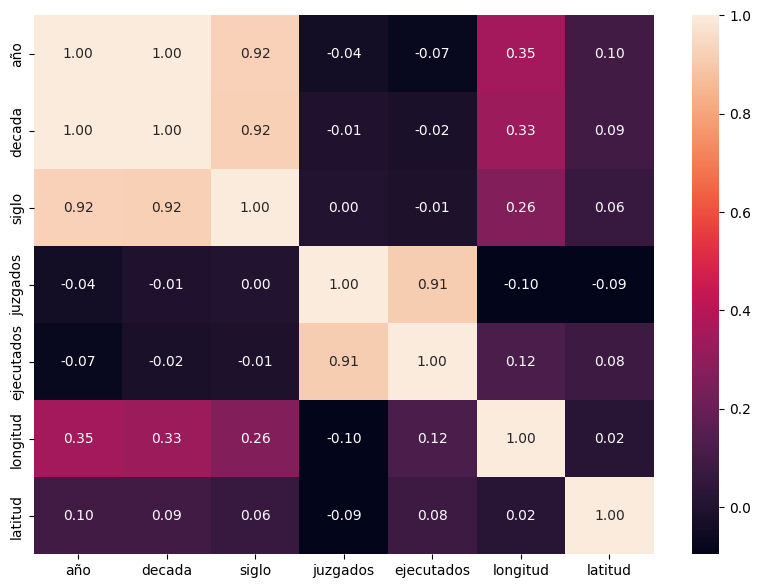

In [ ]:
# Matriz de correlaciones (solo con los atributos numéricos)
trials_sin_texto = trials.drop(["ciudad", "provincia", "region", "pais", "fuente"], axis=1)
corr_matrix = trials_sin_texto.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f')
plt.show()

`ejecutados` solo tiene una correlación clara con `juzgados`, lo cual es lógico. `año`, `decada` y `siglo` dicen prácticamente lo mismo.

### Valores nulos

In [ ]:
trials.isna().sum()

,0
año,931
decada,0
siglo,0
juzgados,0
ejecutados,3826
ciudad,5213
provincia,1047
region,159
pais,0
longitud,5803


Faltan muchas coordenadas y ciudades, y de más de un tercio de los juicios no sabemos cuántas personas fueron ejecutadas.

## 4. Exposición del objetivo

Sabemos cómo terminaron muchos de los juicios, así que es un problema de aprendizaje **supervisado**.

Como `ejecutados` es casi siempre 0 o 1, en vez de predecir el número de ejecuciones vamos a predecir si hubo alguna o no. Es un problema de **clasificación binaria**.

El **target** será un atributo nuevo, `ejecucion`, que vale 1 si se ejecutó al menos a una persona y 0 si no.

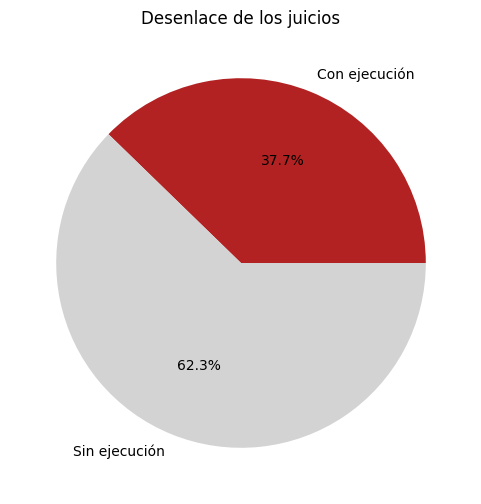

In [ ]:
# Juicios de los que conocemos el desenlace
con_ejecucion = (trials["ejecutados"] > 0).sum()
sin_ejecucion = (trials["ejecutados"] == 0).sum()

plt.figure(figsize=(6, 6))
plt.pie([con_ejecucion, sin_ejecucion], labels=["Con ejecución", "Sin ejecución"], colors=["firebrick", "lightgray"], autopct="%1.1f%%")
plt.title("Desenlace de los juicios")
plt.show()

Un modelo que dijera siempre "sin ejecución" ya acertaría el 62.3% de las veces. Nuestros modelos tienen que superar esa cifra.

Mediremos el rendimiento con el porcentaje de aciertos, la *precission* (cuántas de las ejecuciones que predice son reales) y el *recall* (cuántas de las ejecuciones reales detecta).

$precission = \frac{TP}{TP + FP}$

$recall = \frac{TP}{TP + FN}$

## 5. Preparación de los datos para los algoritmos de Machine Learning

### Limpieza

* Eliminamos las filas sin `ejecutados`, porque no sabemos cómo acabó el juicio.
* Eliminamos `año` y `siglo` (nos quedamos con `decada`, que no tiene nulos), `longitud`, `latitud` y `ciudad` (demasiados nulos), `provincia` (demasiados valores distintos) y `fuente` (no es un dato del juicio).
* Rellenamos los nulos de `region` con el texto `Desconocida`.
* Creamos el target y eliminamos `ejecutados`, para que el modelo no tenga la respuesta delante.

In [ ]:
# Elimina las filas que no tienen el número de ejecutados
trials = trials.dropna(subset=["ejecutados"])

# Elimina los atributos que no vamos a usar
trials = trials.drop(["año", "siglo", "longitud", "latitud", "ciudad", "provincia", "fuente"], axis=1)

# Cambia los nulos de la columna region por el texto "Desconocida"
trials["region"] = trials["region"].fillna("Desconocida")

# Target: 1 si en el juicio se ejecutó al menos a una persona, 0 si no se ejecutó a nadie
trials["ejecucion"] = (trials["ejecutados"] > 0).astype(int)
trials = trials.drop("ejecutados", axis=1)

trials.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7114 entries, 0 to 10939
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   decada     7114 non-null   int64 
 1   juzgados   7114 non-null   int64 
 2   region     7114 non-null   object
 3   pais       7114 non-null   object
 4   ejecucion  7114 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 333.5+ KB


Nos quedan 7114 juicios, ya sin nulos.

### Creación de nuevas variables

Creamos un atributo nuevo que indica si el juicio fue individual o colectivo y miramos su correlación con el target.

In [ ]:
# Juicio colectivo: 1 si se juzgó a más de una persona, 0 si se juzgó a una sola
trials["colectivo"] = (trials["juzgados"] > 1).astype(int)

corr_matrix = (trials.drop(["pais", "region"], axis=1)).corr()
corr_matrix["ejecucion"].sort_values(ascending=False)

,ejecucion
ejecucion,1.000000
colectivo,0.456331
juzgados,0.195869
decada,-0.176430


El atributo nuevo tiene bastante más correlación con el target que `juzgados`, así que nos lo quedamos.

### Codificación, mezcla y separación

Convertimos `pais` y `region` a números creando una columna de ceros y unos para cada lugar, barajamos los datos y los dividimos en entrenamiento (80%) y prueba (20%).

In [ ]:
from sklearn.model_selection import train_test_split

trials = pd.get_dummies(trials, columns=["pais", "region"], dtype=int)
trials = trials.sample(frac=1, random_state=42)

y = trials["ejecucion"]
X = trials.drop("ejecucion", axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(X_train.shape)
print(X_test.shape)

(5691, 110)
(1423, 110)


### Escalado

`decada` tiene valores mucho más grandes que el resto de atributos y eso perjudica a algunos algoritmos. Escalamos `decada` y `juzgados` con `StandardScaler`, ajustándolo solo con los datos de entrenamiento.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Atributos que vamos a escalar (las columnas de 0 y 1 no lo necesitan)
columnas_numericas = ["decada", "juzgados"]

scaler = StandardScaler()
X_train[columnas_numericas] = scaler.fit_transform(X_train[columnas_numericas])
X_test[columnas_numericas] = scaler.transform(X_test[columnas_numericas])

X_train.head()

,decada,juzgados,colectivo,pais_Alemania,pais_Austria,pais_Bélgica,pais_España,pais_Estonia,pais_Finlandia,pais_Francia,...,region_Veneto,region_Vlaanderen,region_Vorarlberg,region_Wallonie,region_Warmian-Masurian,region_Wien,region_Zeeland,region_Zug,region_Zuid-Holland,region_Zurich
6252,-3.384412,-0.169530,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10797,-1.085177,-0.117735,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
80,-2.158154,-0.117735,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7263,-0.012201,0.089448,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4705,0.600928,-0.169530,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 6. Entrenamiento del modelo y comprobación del rendimiento

Vamos a entrenar cuatro modelos y a comprobar el rendimiento de cada uno con **validación cruzada** de 5 particiones, sin tocar el conjunto de prueba hasta el final:

* **SGDClassifier**: modelo lineal.
* **KNeighborsClassifier**: clasifica cada juicio según los que más se le parecen.
* **SVC**: busca la frontera que mejor separa las dos clases.
* **ExtraTreesClassifier**: conjunto de árboles de decisión, parecido a *random forest*.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import SGDClassifier

model_sgdc = SGDClassifier(random_state=24)
model_sgdc.fit(X_train, y_train)

# Validación cruzada: porcentaje de aciertos en cada partición y la media
scores = cross_val_score(model_sgdc, X_train, y_train, cv=5)
print(scores)
print("Media de aciertos: ", scores.mean() * 100, "%")

[0.80860404 0.82601054 0.80755712 0.80316344 0.79173989]
Media de aciertos:  80.74150080775692 %


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier()
model_knn.fit(X_train, y_train)

scores = cross_val_score(model_knn, X_train, y_train, cv=5)
print(scores)
print("Media de aciertos: ", scores.mean() * 100, "%")

[0.8191396  0.83831283 0.83304042 0.82425308 0.83040422]
Media de aciertos:  82.90300281904855 %


In [ ]:
from sklearn.svm import SVC

model_svc = SVC(random_state=18)
model_svc.fit(X_train, y_train)

scores = cross_val_score(model_svc, X_train, y_train, cv=5)
print(scores)
print("Media de aciertos: ", scores.mean() * 100, "%")

[0.83230904 0.85325132 0.82688928 0.82513181 0.82425308]
Media de aciertos:  83.23669052648471 %


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

model_extra = ExtraTreesClassifier(random_state=42)
model_extra.fit(X_train, y_train)

scores = cross_val_score(model_extra, X_train, y_train, cv=5)
print(scores)
print("Media de aciertos: ", scores.mean() * 100, "%")

[0.83845478 0.84710018 0.83655536 0.83216169 0.82952548]
Media de aciertos:  83.67594982803341 %


Los cuatro quedan muy cerca, entre el 80% y el 84% de aciertos. El que más acierta es el ExtraTreesClassifier, así que nos quedamos con él.

### Prueba con los datos de test

In [ ]:
# Número de aciertos y número de fallos con las predicciones sobre el conjunto de test
y_test_pred = model_extra.predict(X_test)
success = (y_test_pred == y_test).sum()
fail = (y_test_pred != y_test).sum()
print("Aciertos: ", success)
print("Fallos: ", fail)
print("Porcentaje de aciertos: ", (success / (success + fail)) * 100, "%")

Aciertos:  1179
Fallos:  244
Porcentaje de aciertos:  82.85312719606466 %


In [ ]:
from sklearn.metrics import confusion_matrix

# Cada fila representa a las instancias reales y cada columna a las predicciones
conf_matrix = confusion_matrix(y_test, y_test_pred)
print(conf_matrix)

TP = conf_matrix[1, 1]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

print("Precission: ", TP / (TP + FP))
print("Recall: ", TP / (TP + FN))

[[818  85]
 [159 361]]
Precission:  0.8094170403587444
Recall:  0.6942307692307692


El modelo acierta el 82.85% de los juicios de prueba, casi lo mismo que en validación cruzada. Cuando predice ejecución acierta el 81% de las veces, pero solo detecta el 69% de las ejecuciones reales.

## 7. Conclusiones

* El modelo elegido (ExtraTreesClassifier) acierta el 82.9% de los juicios de prueba, frente al 62% que se acertaría diciendo siempre "sin ejecución". Ha aprendido algo de los datos, aunque falla en uno de cada seis juicios.
* Su punto débil es el *recall*: se le escapan casi un tercio de los juicios que acabaron en ejecución.
* Los cuatro algoritmos son muy distintos y todos quedan entre el 80% y el 84%, así que lo que limita el resultado parecen ser los datos y no el algoritmo.
* Los datos tienen limitaciones: solo se conoce el desenlace de 7114 de los 10940 juicios y no sabemos nada de las personas juzgadas.
* El atributo `colectivo` que creamos tiene bastante más relación con el resultado que `juzgados`: los juicios colectivos acabaron en ejecución con más frecuencia.